# Proyecto 3: Optimización de Riego con Enjambre de Partículas (PSO)
**Materia:** Tópicos de IA  
**Integrantes:**  
- **Manjarrez Olivas Mariana**  
- **Cervantes Araujo Carlos Iván**  

## Descripción del problema y modelado
En la zona agrícola de Guasave, Sinaloa, el agua de riego normalmente se distribuye parejo en todo el terreno, sin tomar mucho en cuenta las diferencias que hay dentro de cada parcela. Aunque Guasave es una llanura costera plana con elevaciones de entre 10 y 50 metros sobre el nivel del mar, esas pequeñas variaciones de altura cambian hacia dónde escurre el agua y qué partes retienen más humedad.

También influye el tipo de cultivo. En la región predominan el maíz grano (que abarca el 21.7% de la producción del estado), el tomate rojo (9.9%) y el chile verde. El maíz aguanta un poco más las variaciones, pero el tomate y el chile resienten muy rápido cualquier falta de agua o exceso de sales. Si a esto le agregamos que los suelos han perdido materia orgánica en los últimos 20 años (bajando de 1.5% a menos del 1%) y que hay zonas con mal drenaje donde sube la salinidad (hasta 3.95 dS/m), poner sensores al azar no sirve: o dejamos puntos críticos sin medir o gastamos de más encimando sensores donde no hacen falta.

Para resolver esto modelamos el terreno como un espacio continuo usando las coordenadas (Latitud y Longitud) de 100 parcelas muestreadas en Guasave. Cada partícula del enjambre representa una propuesta completa de dónde poner $K$ sensores, por lo que trabajamos en una dimensión de $D = 2 \times K$. La función objetivo mide la distancia de cada parcela hasta su sensor más cercano y la multiplica por un peso de criticidad (`PesCri`). Ese peso sube si el suelo está muy seco, si tiene mucha sal, si está más alto o si tiene sembrado tomate o chile. Además, metimos una penalización si dos sensores quedan a menos de 0.85 km entre ellos para que no se amontonen en una sola zona.

## Justificación del método PSO
Decidimos usar PSO en lugar de algoritmos genéticos o búsqueda tabú porque las coordenadas geográficas son valores continuos. PSO mueve las partículas directamente en un espacio real usando vectores de posición y velocidad, sin tener que cuadricular el mapa ni usar operadores complicados de cruza. Aparte, como cada partícula actualiza su rumbo combinando su inercia con su mejor posición personal y la mejor del grupo, el algoritmo revisa rápido todo el valle y se va cerrando sobre las zonas con mayor estrés hídrico sin quedarse atorado tan fácil en óptimos locales.

In [1]:
# Primero Importamos las libreria y cargamos los datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

# Semilla fija para que las corridas sean reproducibles en las pruebas
np.random.seed(67)

# Datos crudos de las 100 parcelas de Guasave (Humedad, Cultivo, Elevacion, Salinidad, Temp, Lat, Lon)
LisRegRaw = [
    (35.4, 'Maíz', 32.1, 1.18, 30.9, 25.525269, -108.480884), (20.0, 'Maíz', 40.8, 3.3, 27.5, 25.600618, -108.519701), (43.3, 'Maíz', 21.9, 1.17, 31.8, 25.577411, -108.465669), (36.3, 'Maíz', 41.7, 2.93, 25.3, 25.616337, -108.470516), (17.3, 'Chile', 31.8, 1.91, 29.1, 25.522286, -108.480179),
    (22.0, 'Chile', 32.6, 1.62, 35.2, 25.569703, -108.501312), (19.1, 'Chile', 21.4, 3.9, 25.7, 25.579862, -108.510461), (28.3, 'Tomate', 18.1, 0.54, 37.0, 25.536138, -108.45039), (20.1, 'Chile', 36.7, 2.54, 25.9, 25.543936, -108.464508), (6.0, 'Maíz', 31.9, 0.85, 33.2, 25.568602, -108.436378),
    (41.7, 'Chile', 45.1, 2.52, 21.6, 25.615186, -108.428339), (19.5, 'Tomate', 12.2, 2.18, 28.8, 25.601332, -108.469617), (22.3, 'Maíz', 34.2, 1.35, 34.5, 25.57396, -108.487928), (11.0, 'Chile', 49.4, 3.75, 35.0, 25.551895, -108.489976), (40.8, 'Chile', 31.9, 1.32, 20.7, 25.612299, -108.422137),
    (6.9, 'Tomate', 20.7, 1.8, 22.7, 25.562234, -108.464749), (20.6, 'Maíz', 46.0, 2.39, 38.8, 25.544452, -108.430058), (32.3, 'Tomate', 29.9, 2.22, 25.4, 25.610699, -108.480493), (39.2, 'Tomate', 25.0, 1.66, 29.0, 25.617916, -108.447962), (25.9, 'Maíz', 42.2, 0.56, 30.1, 25.566207, -108.509164),
    (9.2, 'Maíz', 39.8, 2.23, 24.9, 25.577242, -108.452329), (8.1, 'Maíz', 36.7, 1.98, 32.5, 25.601426, -108.507991), (28.2, 'Maíz', 10.6, 0.95, 38.8, 25.578539, -108.502035), (5.5, 'Tomate', 23.1, 1.49, 25.9, 25.545519, -108.503949), (16.2, 'Chile', 14.4, 2.97, 22.8, 25.585059, -108.452106),
    (11.2, 'Tomate', 16.9, 1.5, 32.4, 25.576974, -108.502348), (39.6, 'Tomate', 18.7, 3.92, 20.7, 25.597132, -108.476836), (21.0, 'Chile', 11.1, 3.25, 26.9, 25.530344, -108.485571), (8.2, 'Chile', 23.9, 1.28, 30.6, 25.56348, -108.445757), (13.9, 'Tomate', 21.2, 0.64, 26.2, 25.593413, -108.491781),
    (16.2, 'Chile', 22.4, 0.66, 36.5, 25.571965, -108.492518), (43.3, 'Tomate', 45.6, 1.56, 22.0, 25.615266, -108.487209), (43.3, 'Chile', 49.7, 1.9, 34.8, 25.558179, -108.518102), (29.6, 'Maíz', 18.2, 1.17, 29.1, 25.568482, -108.442325), (18.9, 'Maíz', 29.9, 2.02, 36.8, 25.618887, -108.518957),
    (32.6, 'Tomate', 35.0, 0.96, 27.7, 25.576783, -108.517817), (31.7, 'Chile', 23.4, 1.17, 25.5, 25.568994, -108.472747), (10.7, 'Maíz', 10.3, 2.44, 25.3, 25.614042, -108.493219), (42.7, 'Chile', 10.1, 1.36, 35.3, 25.600457, -108.496185), (22.9, 'Maíz', 20.1, 2.92, 29.5, 25.615359, -108.497118),
    (29.1, 'Chile', 12.3, 2.89, 23.0, 25.556258, -108.430394), (33.2, 'Chile', 14.0, 0.78, 29.8, 25.540828, -108.460249), (35.6, 'Chile', 44.6, 3.56, 30.5, 25.607947, -108.464478), (9.5, 'Maíz', 41.4, 2.6, 34.8, 25.541347, -108.453822), (13.6, 'Chile', 40.7, 0.94, 26.6, 25.53381, -108.519463),
    (42.0, 'Chile', 43.6, 2.18, 25.2, 25.570288, -108.449353), (25.6, 'Chile', 11.0, 1.84, 25.5, 25.594593, -108.509253), (33.2, 'Tomate', 18.9, 3.0, 26.4, 25.61416, -108.455096), (44.3, 'Tomate', 24.9, 3.88, 27.4, 25.603546, -108.489592), (35.9, 'Chile', 13.1, 1.28, 30.6, 25.59215, -108.519166),
    (31.1, 'Chile', 34.3, 0.74, 26.6, 25.599119, -108.497474), (9.9, 'Tomate', 20.7, 0.6, 26.5, 25.541617, -108.420215), (24.2, 'Tomate', 20.1, 0.94, 36.6, 25.546029, -108.501044), (40.8, 'Tomate', 45.8, 0.96, 31.5, 25.601962, -108.439458), (11.2, 'Maíz', 30.7, 1.49, 28.1, 25.590474, -108.495022),
    (29.1, 'Maíz', 27.9, 2.99, 35.8, 25.541885, -108.438006), (37.7, 'Tomate', 10.2, 3.84, 27.5, 25.566371, -108.471062), (35.7, 'Maíz', 11.4, 3.89, 24.7, 25.577648, -108.496633), (23.9, 'Maíz', 44.9, 1.81, 28.3, 25.603601, -108.44998), (40.2, 'Chile', 11.1, 1.32, 25.2, 25.559236, -108.518247),
    (6.3, 'Maíz', 21.7, 1.32, 40.0, 25.551866, -108.445206), (44.9, 'Chile', 14.2, 1.52, 36.1, 25.533315, -108.423948), (43.1, 'Maíz', 25.7, 1.61, 37.2, 25.544761, -108.468132), (31.3, 'Tomate', 39.9, 0.87, 32.5, 25.579027, -108.490022), (11.9, 'Chile', 40.0, 3.25, 29.4, 25.61422, -108.448072),
    (22.5, 'Chile', 22.2, 2.33, 25.7, 25.547955, -108.450106), (23.1, 'Chile', 13.9, 3.02, 22.0, 25.523878, -108.502427), (31.2, 'Tomate', 30.0, 1.34, 30.6, 25.533115, -108.456761), (20.0, 'Maíz', 15.3, 2.13, 29.1, 25.6049, -108.492247), (10.3, 'Maíz', 42.1, 2.92, 28.2, 25.604552, -108.517331),
    (21.4, 'Maíz', 45.1, 0.55, 35.5, 25.561935, -108.519274), (26.9, 'Maíz', 32.3, 3.4, 25.7, 25.555427, -108.42319), (22.5, 'Chile', 11.8, 1.37, 32.4, 25.52675, -108.510972), (40.9, 'Chile', 32.0, 3.11, 28.3, 25.612885, -108.484575), (19.0, 'Tomate', 43.9, 3.19, 38.1, 25.611875, -108.508331),
    (5.1, 'Chile', 26.5, 1.8, 20.3, 25.579335, -108.467927), (19.9, 'Maíz', 26.1, 3.81, 35.5, 25.576945, -108.502777), (27.9, 'Maíz', 37.6, 0.88, 31.5, 25.611043, -108.508468), (14.6, 'Tomate', 45.0, 1.12, 24.7, 25.531398, -108.506489), (33.7, 'Chile', 22.0, 1.19, 22.1, 25.548237, -108.516646),
    (15.9, 'Tomate', 30.1, 3.3, 23.1, 25.554671, -108.501926), (44.8, 'Maíz', 31.6, 2.13, 34.7, 25.521859, -108.513298), (26.6, 'Maíz', 38.7, 1.25, 32.8, 25.613286, -108.490537), (26.7, 'Tomate', 41.5, 3.21, 33.8, 25.559703, -108.441534), (6.4, 'Maíz', 47.4, 3.57, 36.4, 25.544613, -108.504298),
    (12.7, 'Maíz', 34.3, 1.06, 30.8, 25.544125, -108.453288), (22.3, 'Tomate', 35.1, 3.19, 20.0, 25.539745, -108.45725), (27.1, 'Tomate', 46.7, 2.02, 38.7, 25.574685, -108.44159), (24.6, 'Chile', 32.2, 1.84, 32.8, 25.544383, -108.422493), (31.2, 'Tomate', 28.8, 3.22, 31.0, 25.582556, -108.505056),
    (31.5, 'Chile', 39.3, 3.95, 38.9, 25.539601, -108.468409), (10.7, 'Tomate', 37.8, 2.88, 30.1, 25.578598, -108.509114), (35.6, 'Tomate', 49.4, 3.68, 38.0, 25.589127, -108.497769), (9.9, 'Maíz', 23.5, 3.07, 25.1, 25.528027, -108.472023), (26.2, 'Chile', 44.3, 2.69, 38.1, 25.537541, -108.497964),
    (29.7, 'Tomate', 14.5, 1.54, 28.3, 25.567005, -108.462403), (28.9, 'Maíz', 39.9, 1.64, 31.4, 25.533387, -108.472275), (25.5, 'Maíz', 37.8, 0.87, 20.8, 25.555069, -108.457875), (17.5, 'Chile', 23.3, 1.58, 22.3, 25.569962, -108.45769), (12.5, 'Tomate', 43.7, 1.65, 23.3, 25.570974, -108.420756)
]

ColNom = ['HSuelo', 'TipCul', 'ElevacionT', 'SSuelo', 'TemAmb', 'LatGps', 'LonGps']
DCampo = pd.DataFrame(LisRegRaw, columns=ColNom)

print("Total de registros cargados:", len(DCampo))
DCampo.head()

Total de registros cargados: 100


,HSuelo,TipCul,ElevacionT,SSuelo,TemAmb,LatGps,LonGps
0,35.4,Maíz,32.1,1.18,30.9,25.525269,-108.480884
1,20.0,Maíz,40.8,3.30,27.5,25.600618,-108.519701
2,43.3,Maíz,21.9,1.17,31.8,25.577411,-108.465669
3,36.3,Maíz,41.7,2.93,25.3,25.616337,-108.470516
4,17.3,Chile,31.8,1.91,29.1,25.522286,-108.480179


## Índice de prioridad de riego y modulación de PSO
Antes de lanzar el enjambre calculamos la columna `PesCri` para darle prioridad a las parcelas más urgentes. Aquí combinamos el déficit de humedad, la salinidad, la elevación y un factor por cultivo (dándole más peso al tomate y al chile). En el siguiente bloque están programadas las funciones para calcular este peso, evaluar la función objetivo y correr las iteraciones del enjambre.

In [3]:
# Funciones modulares para el cpalculo de criticidad y ejecucipon del PSO

def CalPesoCrit(TabAgr):
    ValHum = TabAgr['HSuelo'].values
    ValEle = TabAgr['ElevacionT'].values
    ValSal = TabAgr['SSuelo'].values

    # Pesos por cultivo
    DicCul = {'Tomate': 1.35, 'Chile': 1.20, 'Maíz': 1.00}
    FacCul = TabAgr['TipCul'].map(DicCul).values

    # Normalizaciones sencills entre 0 y 1 aprox
    DefHumedad = np.maximum(0.0, (45.0 - ValHum) / 45.0)
    NivSal = ValSal / 4.0
    VarEle = (ValEle - 10.0) / 40.0

    # Combinacion pondersda
    PesCri = FacCul * (0.50 * DefHumedad + 0.30 * NivSal + 0.20 * VarEle)
    return PesCri

# Agregamos la columna calculada al datsframe pricipal
DCampo['PesCri'] = CalPesoCrit(DCampo)


def FunObjPso(MatPos, CTerreno, PesTer, NSensores):
    # Mide la distancia de las parcelas al sensor mas proximo e incluye penalizaciones si estan muy encimados
    TEnjambre = MatPos.shape[0]
    VecCos = np.zeros(TEnjambre)

    for i in range(TEnjambre):
        # Acomodamos el vector de la particula en pares (Lat, Lon)
        CSensores = MatPos[i].reshape(NSensores, 2)

        # Matriz de distancias eclidianas convertidas aprox a kilometros (1 grado ~ 111 km)
        MatDis = cdist(CTerreno, CSensores, metric='euclidean') * 111.0

        # Cada parcela se asocia al sensor que le quede mas cerca
        DisMin = np.min(MatDis, axis=1)

        # Costo principal: distancia al cuadrado multiplicada por la criticidad del punto
        CosCobertura = np.sum(PesTer * (DisMin ** 2))

        # Castigo si hay sensores a menos de 0.85 km entre ellos
        PenCercania = 0.0
        if NSensores > 1:
            DisEntSen = cdist(CSensores, CSensores, metric='euclidean') * 111.0
            for s1 in range(NSensores):
                for s2 in range(s1 + 1, NSensores):
                    if DisEntSen[s1, s2] < 0.85:
                        PenCercania += (0.85 - DisEntSen[s1, s2]) * 6.0

        VecCos[i] = CosCobertura + PenCercania

    return VecCos


def EjeOptPso(SubTab, NSensores=5, TEnjambre=30, MaxIte=80, PesIne=0.72, CoeCognitivo=1.45, CoeSocial=1.45):
    CTerreno = SubTab[['LatGps', 'LonGps']].values
    PesTer = SubTab['PesCri'].values

    # Limites de busqueda segun el pedazo de terreno en el que este
    LimInf = np.array([CTerreno[:, 0].min(), CTerreno[:, 1].min()] * NSensores)
    LimSup = np.array([CTerreno[:, 0].max(), CTerreno[:, 1].max()] * NSensores)
    DimTot = NSensores * 2

    # Inicializamos posiciones y velocidades al azar
    MatPos = np.random.uniform(LimInf, LimSup, (TEnjambre, DimTot))
    MatVel = np.zeros((TEnjambre, DimTot))

    # Primera evaluacion
    CosAct = FunObjPso(MatPos, CTerreno, PesTer, NSensores)
    MejPosInd = MatPos.copy()
    MejCosInd = CosAct.copy()

    IdxMej = np.argmin(MejCosInd)
    MejPosGlo = MejPosInd[IdxMej].copy()
    MejCosGlo = MejCosInd[IdxMej]

    HistConvergencia = [MejCosGlo]

    # Ciclo de iteraciones del enjambre
    for it in range(MaxIte):
        AleUno = np.random.rand(TEnjambre, DimTot)
        AleDos = np.random.rand(TEnjambre, DimTot)

        # Ecuacion clasica de velocidad en PSO
        MatVel = (PesIne * MatVel +
                  CoeCognitivo * AleUno * (MejPosInd - MatPos) +
                  CoeSocial * AleDos * (MejPosGlo - MatPos))

        # Actualizamos posicipon cuidando que no se salga de nuetro mapa
        MatPos = np.clip(MatPos + MatVel, LimInf, LimSup)
        CosAct = FunObjPso(MatPos, CTerreno, PesTer, NSensores)

        # Actualizamos mejores personales (pBest)
        ConMej = CosAct < MejCosInd
        MejPosInd[ConMej] = MatPos[ConMej]
        MejCosInd[ConMej] = CosAct[ConMej]

        # Actualizamos mejor global (gBest)
        if np.min(MejCosInd) < MejCosGlo:
            IdxMej = np.argmin(MejCosInd)
            MejPosGlo = MejPosInd[IdxMej].copy()
            MejCosGlo = MejCosInd[IdxMej]

        HistConvergencia.append(MejCosGlo)

    return MejPosGlo.reshape(NSensores, 2), MejCosGlo, HistConvergencia

## Pruebas funcionales
Para probar que el algoritmo responde bien en diferentes escenarios y no solo con la tabla completa, armamos tres muestras de corrida filtrando distintas secciones del terreno. En la primera (`M1`) agarramos solo las primeras 30 parcelas para ver cómo acomoda 4 sensores en un área chica. Para la segunda (`M2`) filtramos únicamente los terrenos con salinidad alta (de 2.2 dS/m para arriba, que son 40 parcelas) usando 5 sensores para vigilar las zonas con mal drenaje. Ya en la tercera (`M3`) metimos las 100 parcelas completas de Guasave con una red de 8 sensores.

In [4]:
# Ejecución de las 3 muestras de corrida y los reportes en la consola

# Definicion de las 3 secciones de prueba
M1 = DCampo.iloc[:30].copy()
M2 = DCampo[DCampo['SSuelo'] >= 2.2].copy()
M3 = DCampo.copy()

LisPru = [
    ("Muestra 1: Sección 30 Parcelas", M1, 4),
    ("Muestra 2: Zonas Salinidad Alta (>=2.2 dS/m)", M2, 5),
    ("Muestra 3: Campo Completo Guasave (100 puntos)", M3, 8)
]

DicRes = {}
LisRep = []

for NomMue, SubDat, CanSen in LisPru:
    COptima, CosFin, HistConvergencia = EjeOptPso(SubDat, NSensores=CanSen, TEnjambre=35, MaxIte=90)
    CosIni = HistConvergencia[0]
    PMejora = ((CosIni - CosFin) / CosIni) * 100.0

    # Calculamos radio promedio de cobertura en km hacia el sensor mas cercano
    CTerreno = SubDat[['LatGps', 'LonGps']].values
    DisMin = np.min(cdist(CTerreno, COptima) * 111.0, axis=1)
    DisPro = np.mean(DisMin)

    DicRes[NomMue] = {
        'SubDat': SubDat,
        'COptima': COptima,
        'HistConvergencia': HistConvergencia,
        'CosIni': CosIni,
        'CosFin': CosFin,
        'PMejora': PMejora,
        'DisPro': DisPro
    }

    LisRep.append({
        'Corrida': NomMue,
        'Parcelas': len(SubDat),
        'Sensores': CanSen,
        'Costo_Inicial': round(CosIni, 3),
        'Costo_Final': round(CosFin, 3),
        'Mejora (%)': round(PMejora, 2),
        'Dist_Media_km': round(DisPro, 3)
    })

    print("=" * 50)
    print(f" REPORTE -> {NomMue}")
    print("=" * 50)
    print(f" Parcelas evaluadas : {len(SubDat)} | Sensores colocados: {CanSen}")
    print(f" Costo inicial      : {CosIni:.4f}")
    print(f" Costo optimizado   : {CosFin:.4f}  (Reducción del {PMejora:.2f}%)")
    print(f" Distancia media al sensor más cercano: {DisPro:.3f} km")
    print(" Coordenadas recomendadas (Latitud, Longitud):")
    for idx, par in enumerate(COptima, 1):
        print(f"   Sensor {idx}: [{par[0]:.5f}, {par[1]:.5f}]")
    print("\n")

# Tabla comparativa
TabResFin = pd.DataFrame(LisRep)
TabResFin

 REPORTE -> Muestra 1: Sección 30 Parcelas
 Parcelas evaluadas : 30 | Sensores colocados: 4
 Costo inicial      : 99.7324
 Costo optimizado   : 69.3871  (Reducción del 30.43%)
 Distancia media al sensor más cercano: 1.954 km
 Coordenadas recomendadas (Latitud, Longitud):
   Sensor 1: [25.55888, -108.45069]
   Sensor 2: [25.58380, -108.50443]
   Sensor 3: [25.53839, -108.48984]
   Sensor 4: [25.60506, -108.45870]


 REPORTE -> Muestra 2: Zonas Salinidad Alta (>=2.2 dS/m)
 Parcelas evaluadas : 40 | Sensores colocados: 5
 Costo inicial      : 131.4485
 Costo optimizado   : 81.8091  (Reducción del 37.76%)
 Distancia media al sensor más cercano: 1.654 km
 Coordenadas recomendadas (Latitud, Longitud):
   Sensor 1: [25.59417, -108.50522]
   Sensor 2: [25.54271, -108.46220]
   Sensor 3: [25.60778, -108.46102]
   Sensor 4: [25.54261, -108.49710]
   Sensor 5: [25.55699, -108.43693]


 REPORTE -> Muestra 3: Campo Completo Guasave (100 puntos)
 Parcelas evaluadas : 100 | Sensores colocados: 8
 Cos

,Corrida,Parcelas,Sensores,Costo_Inicial,Costo_Final,Mejora (%),Dist_Media_km
0,Muestra 1: Sección 30 Parcelas,30,4,99.732,69.387,30.43,1.954
1,Muestra 2: Zonas Salinidad Alta (>=2.2 dS/m),40,5,131.448,81.809,37.76,1.654
2,Muestra 3: Campo Completo Guasave (100 puntos),100,8,205.354,108.035,47.39,1.300


## Visualización de resultados y convergencia
En este último bloque graficamos lo que salió en las tres corridas. Los mapas de arriba muestran las parcelas según su cultivo, el tamaño de cada punto representa qué tanta urgencia de riego tiene (`PesCri`) y las estrellas amarillas indican dónde quedaron los sensores al final. En las gráficas de abajo se ve cómo fue bajando el valor de la función de costo conforme avanzaban las iteraciones.

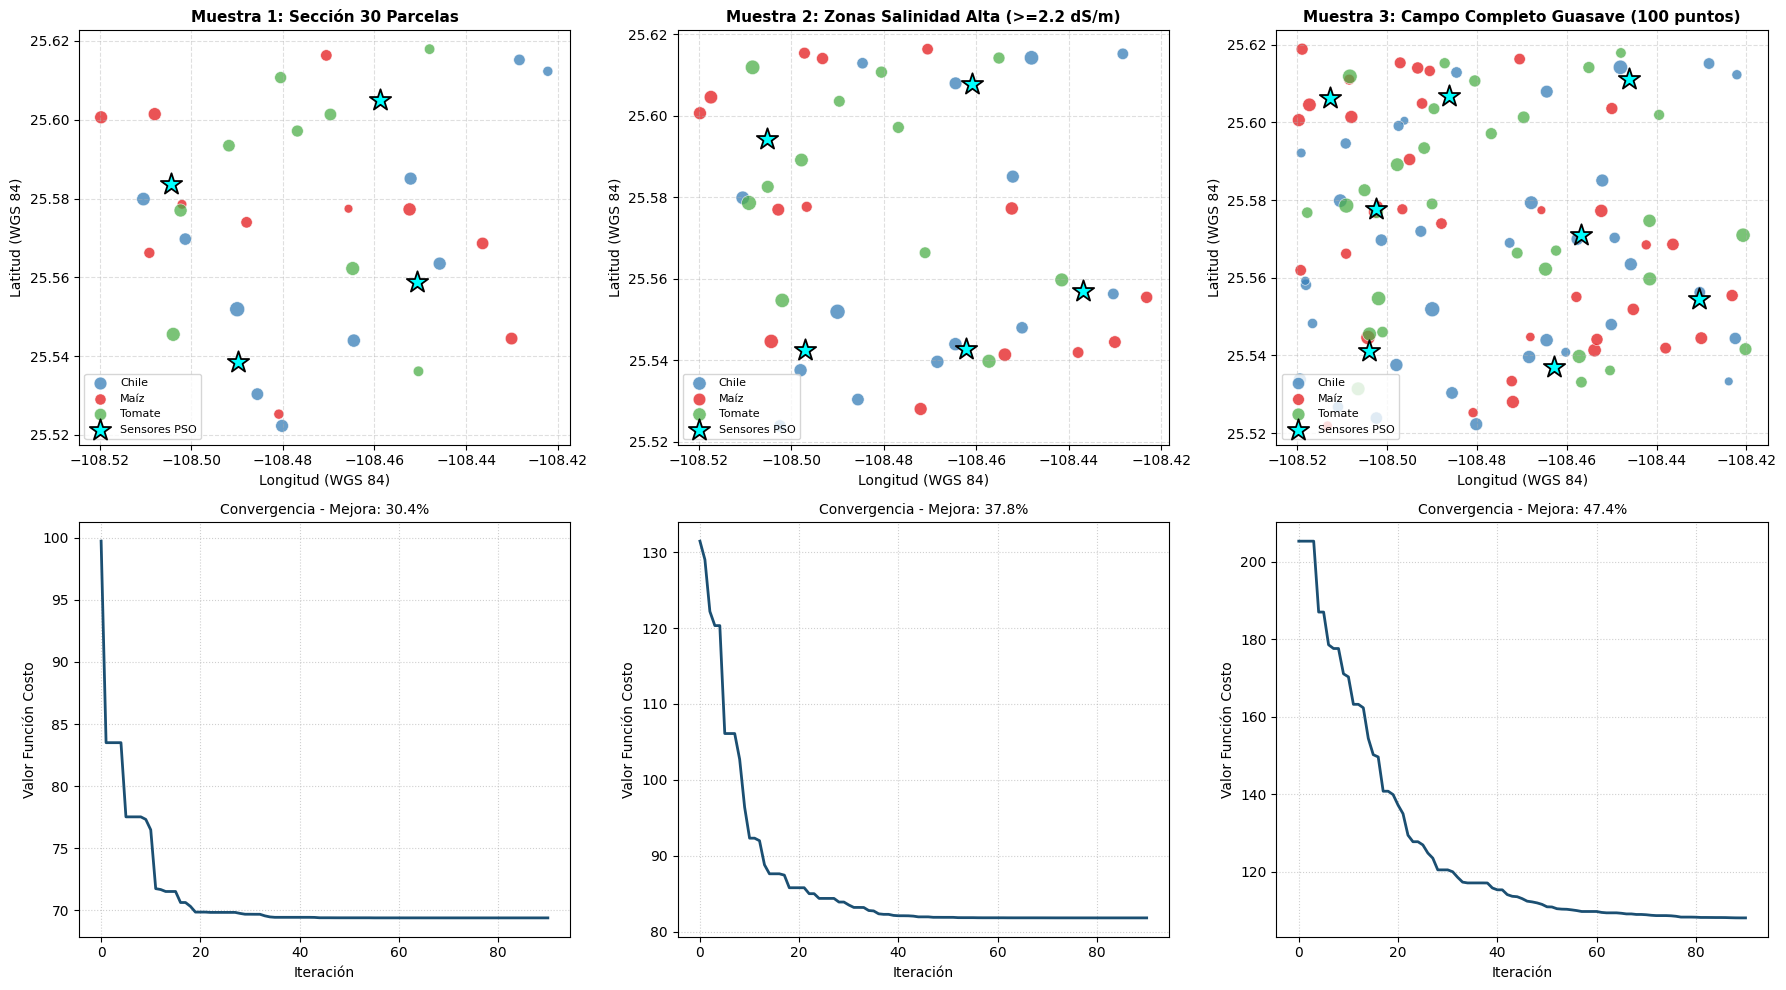

In [7]:
# Gráficas de distribución espacial de sensores

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
ColCul = {'Maíz': '#e41a1c', 'Chile': '#377eb8', 'Tomate': '#4daf4a'}

for idx, (NomMue, DatMue) in enumerate(DicRes.items()):
    SubDat = DatMue['SubDat']
    COptima = DatMue['COptima']
    HistConvergencia = DatMue['HistConvergencia']

    # Grafica superior: Mapa de ubicacion de sensores
    ax_map = axes[0, idx]
    for cul, grp in SubDat.groupby('TipCul'):
        ax_map.scatter(
            grp['LonGps'], grp['LatGps'],
            c=ColCul.get(cul, 'gray'),
            s=grp['PesCri'] * 90 + 25,
            alpha=0.75, label=cul, edgecolors='w', linewidth=0.5
        )

    # Dibujar sensores optimizados
    ax_map.scatter(
        COptima[:, 1], COptima[:, 0],
        c='cyan', marker='*', s=260,
        edgecolors='black', linewidth=1.3, label='Sensores PSO', zorder=5
    )

    ax_map.set_title(NomMue, fontsize=11, fontweight='bold')
    ax_map.set_xlabel('Longitud (WGS 84)')
    ax_map.set_ylabel('Latitud (WGS 84)')
    ax_map.grid(True, linestyle='--', alpha=0.4)
    ax_map.legend(loc='lower left', fontsize=8)

    # Grafica inferior: Curva de convergencia del costo
    ax_con = axes[1, idx]
    ax_con.plot(HistConvergencia, color='#1b4f72', linewidth=2)
    ax_con.set_title(f"Convergencia - Mejora: {DatMue['PMejora']:.1f}%", fontsize=10)
    ax_con.set_xlabel('Iteración')
    ax_con.set_ylabel('Valor Función Costo')
    ax_con.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Conclusiones
Con las tres corridas comprobamos que el algoritmo PSO logra acomodar los sensores bajando el costo inicial entre un 30% y un 47% dependiendo del tamaño de la muestra. Donde más se notó el ajuste fue en la prueba de salinidad crítica (`M2`), porque los suelos salinos tienden a agruparse en ciertas franjas y el enjambre movió rápido los sensores hacia esos puntos, mientras que en el mapa completo (`M3`) la penalización por cercanía evitó que los 8 sensores se empalmaran.

Trabajar con coordenadas continuas en PSO resultó mucho más directo que andar probando ubicaciones a mano, y meter las variables del suelo dentro del peso `PesCri` hizo que la red de sensores se cargara hacia los cultivos más delicados en lugar de quedar como una cuadrícula pareja. Como mejora a futuro, si se contara con el rango máximo de transmisión de las antenas o el costo de instalación por punto, se podría sumar esa restricción en la función objetivo para asegurar que todos los sensores se comuniquen bien con la base.